# Notebook 01 — Cấp 1: Random Baseline (`RandomAgent`)

**Câu hỏi nghiên cứu trọng tâm:**
- Lợi thế đi trước (**First-Player Advantage**) trên bàn cờ Caro 11×11 lớn đến mức nào khi hai bên chơi hoàn toàn ngẫu nhiên?
- Thu hẹp không gian lấy mẫu về vùng lân cận (`candidate_radius=2`) có giúp tăng tốc hình thành chuỗi thắng hay thay đổi tỷ lệ thắng so với uniform toàn bàn hay không?


## 1. Thiết lập môi trường & Khai báo phần cứng


In [1]:
import ctypes
import json
import math
import os
import platform
import random
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1. CẤU HÌNH CHẾ ĐỘ CHẠY & SEED TÁI LẬP
#    - RUN_MODE = "quick": kiểm thử & benchmark nhanh (10-40 giây)
#    - RUN_MODE = "full" : chạy quy mô lớn (50-100+ ván / full training)
# ------------------------------------------------------------------
RUN_MODE = os.environ.get("CARO_NB_MODE", "quick").strip().lower()
assert RUN_MODE in ("quick", "full"), f"RUN_MODE không hợp lệ: {RUN_MODE}"

BASE_SEED = 42
# Tập seed đánh giá cuối cùng độc lập (tuyệt đối không dùng chọn siêu tham số)
FINAL_BENCHMARK_SEEDS = [9001, 9002, 9003, 9004, 9005]

# 2. Tự động nhận diện môi trường (VS Code Local vs Google Colab)
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")
    colab_proj = Path("/content/drive/MyDrive/csttnt_nang_cao/caro_ai_11x11")
    if colab_proj.exists():
        os.chdir(colab_proj)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
LOGS_DIR = PROJECT_ROOT / "results" / "logs"
CHECKPOINTS_DIR = PROJECT_ROOT / "checkpoints"
DATA_DIR = PROJECT_ROOT / "data"
for _d in (TABLES_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR, DATA_DIR):
    _d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


def _get_system_ram_gb() -> str:
    try:
        if platform.system() == "Windows":
            class _MemStatus(ctypes.Structure):
                _fields_ = [
                    ("dwLength", ctypes.c_ulong),
                    ("dwMemoryLoad", ctypes.c_ulong),
                    ("ullTotalPhys", ctypes.c_ulonglong),
                    ("ullAvailPhys", ctypes.c_ulonglong),
                    ("ullTotalPageFile", ctypes.c_ulonglong),
                    ("ullAvailPageFile", ctypes.c_ulonglong),
                    ("ullTotalVirtual", ctypes.c_ulonglong),
                    ("ullAvailVirtual", ctypes.c_ulonglong),
                    ("ullAvailExtendedVirtual", ctypes.c_ulonglong),
                ]
            st = _MemStatus()
            st.dwLength = ctypes.sizeof(_MemStatus)
            ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(st))
            return f"{st.ullTotalPhys / (1024**3):.1f} GB (trống {st.ullAvailPhys / (1024**3):.1f} GB)"
        with open("/proc/meminfo", encoding="utf-8") as f:
            lines = dict(line.split(":", 1) for line in f if ":" in line)
            tot = int(lines["MemTotal"].strip().split()[0]) / (1024**2)
            return f"{tot:.1f} GB"
    except Exception:
        return "N/A"


def _get_process_ram_mb() -> float:
    try:
        if platform.system() == "Windows":
            class _PMC(ctypes.Structure):
                _fields_ = [
                    ("cb", ctypes.c_ulong),
                    ("PageFaultCount", ctypes.c_ulong),
                    ("PeakWorkingSetSize", ctypes.c_size_t),
                    ("WorkingSetSize", ctypes.c_size_t),
                    ("QuotaPeakPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaPeakNonPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaNonPagedPoolUsage", ctypes.c_size_t),
                    ("PagefileUsage", ctypes.c_size_t),
                    ("PeakPagefileUsage", ctypes.c_size_t),
                ]
            pmc = _PMC()
            pmc.cb = ctypes.sizeof(_PMC)
            h = ctypes.windll.kernel32.GetCurrentProcess()
            if ctypes.windll.psapi.GetProcessMemoryInfo(h, ctypes.byref(pmc), pmc.cb):
                return round(pmc.WorkingSetSize / (1024**2), 1)
        else:
            import resource
            return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0, 1)
    except Exception:
        pass
    return -1.0


# 3. Khai báo tài nguyên phần cứng (Mục 3.4 & 3.5 đề cương)
try:
    import torch
    TORCH_INFO = f"PyTorch {torch.__version__} | CUDA={torch.cuda.is_available()}"
    if torch.cuda.is_available():
        TORCH_INFO += f" ({torch.cuda.get_device_name(0)})"
except Exception:
    TORCH_INFO = "PyTorch not available"

HW_INFO = {
    "run_mode": RUN_MODE,
    "os": f"{platform.system()} {platform.release()}",
    "python": platform.python_version(),
    "cpu_cores": os.cpu_count(),
    "processor": platform.processor() or platform.machine(),
    "system_ram": _get_system_ram_gb(),
    "process_ram_mb": _get_process_ram_mb(),
    "accelerator": TORCH_INFO,
    "base_seed": BASE_SEED,
    "project_root": str(PROJECT_ROOT),
}
display(pd.DataFrame([HW_INFO]).T.rename(columns={0: "Giá trị"}))


,Giá trị
run_mode,quick
os,Windows 10
python,3.11.9
cpu_cores,20
processor,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
system_ram,15.7 GB (trống 1.9 GB)
process_ram_mb,-1.0
accelerator,PyTorch 2.15.0+cpu | CUDA=False
base_seed,42
project_root,f:\TTNTNC\Caro\caro_ai_11x11


In [2]:
from src.caro_env import CaroEnv


def wilson_ci95(successes: float, n: int) -> tuple[float, float]:
    """Khoảng tin cậy Wilson 95% cho tỷ lệ điểm Score = (W + 0.5*D) / N."""
    if n <= 0:
        return (0.0, 0.0)
    z = 1.959963984540054
    p = max(0.0, min(1.0, successes / n))
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = (z * math.sqrt((p * (1.0 - p) + z * z / (4.0 * n)) / n)) / denom
    return (max(0.0, center - half) * 100.0, min(1.0, center + half) * 100.0)


def save_raw_logs_jsonl(records: list[dict], path: Path) -> Path:
    """Lưu log thi đấu thô từng ván (.jsonl) phục vụ tái lập & phân tích định tính (Mục 3.7 & 5)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for rec in records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    return path


def run_match_series(
    label: str,
    make_a,
    make_b,
    n_games: int = 20,
    openings: list[tuple[int, int]] | None = None,
    board_size: int = 11,
    win_length: int = 5,
    raw_logs_out: list[dict] | None = None,
) -> dict:
    """
    Chạy loạt ván đấu cân bằng 50/50 lượt đi trước (X) và đi sau (O).
    Ghi nhận bảng tổng hợp (W/D/L, Score%, Wilson CI95, avg_ms, p95_ms, avg_search)
    và đẩy log thô từng ván vào `raw_logs_out` nếu được truyền vào.
    """
    t0 = time.perf_counter()
    wins = draws = losses = 0
    times_a, searches_a, moves_list = [], [], []
    wx = lx = dx = wo = lo = do = 0
    x_wins_total = o_wins_total = draws_total = 0

    for g in range(n_games):
        env = CaroEnv(board_size=board_size, win_length=win_length)
        opening_used = []
        if openings:
            m1, m2 = openings[g % len(openings)]
            env.step(m1)
            env.step(m2)
            opening_used = [int(m1), int(m2)]
        agent_a = make_a(g)
        agent_b = make_b(g)
        a_side = 1 if (g % 2 == 0) else -1
        game_times_a, game_searches_a = [], []

        while not env.is_terminal():
            if env.current_player == a_side:
                act = agent_a.select_action(env)
                dt = float(getattr(agent_a, "last_move_time_ms", 0.0))
                sc = float(getattr(agent_a, "last_search_count", 0.0))
                times_a.append(dt)
                searches_a.append(sc)
                game_times_a.append(dt)
                game_searches_a.append(sc)
            else:
                act = agent_b.select_action(env)
            env.step(act)

        moves_list.append(len(env.history))
        if env.winner == 1:
            x_wins_total += 1
        elif env.winner == -1:
            o_wins_total += 1
        else:
            draws_total += 1

        if env.winner == a_side:
            wins += 1
            res_a = "win"
            if a_side == 1:
                wx += 1
            else:
                wo += 1
        elif env.winner == -a_side:
            losses += 1
            res_a = "loss"
            if a_side == 1:
                lx += 1
            else:
                lo += 1
        else:
            draws += 1
            res_a = "draw"
            if a_side == 1:
                dx += 1
            else:
                do += 1

        if raw_logs_out is not None:
            gts = sorted(game_times_a)
            gp95 = gts[int(0.95 * (len(gts) - 1))] if gts else 0.0
            raw_logs_out.append({
                "matchup": label,
                "game_index": g + 1,
                "agent_a": getattr(agent_a, "name", "AgentA"),
                "agent_b": getattr(agent_b, "name", "AgentB"),
                "agent_a_side": "X" if a_side == 1 else "O",
                "opening": opening_used,
                "winner": "X" if env.winner == 1 else ("O" if env.winner == -1 else "Draw"),
                "result_a": res_a,
                "num_moves": len(env.history),
                "avg_ms_a": round(statistics.mean(game_times_a), 3) if game_times_a else 0.0,
                "p95_ms_a": round(gp95, 3),
                "avg_search_a": round(statistics.mean(game_searches_a), 2) if game_searches_a else 0.0,
                "history": [int(m) for m in env.history],
            })

    score_pts = wins + 0.5 * draws
    score_pct = 100.0 * score_pts / max(1, n_games)
    ci_lo, ci_hi = wilson_ci95(score_pts, n_games)
    ts = sorted(times_a)
    p95 = ts[int(0.95 * (len(ts) - 1))] if ts else 0.0

    return {
        "matchup": label,
        "games": n_games,
        "wins": wins,
        "draws": draws,
        "losses": losses,
        "score_pct": round(score_pct, 2),
        "ci95_low": round(ci_lo, 2),
        "ci95_high": round(ci_hi, 2),
        "as_X": f"{wx}W-{dx}D-{lx}L",
        "as_O": f"{wo}W-{do}D-{lo}L",
        "x_win_pct": round(100.0 * x_wins_total / max(1, n_games), 1),
        "o_win_pct": round(100.0 * o_wins_total / max(1, n_games), 1),
        "avg_moves": round(statistics.mean(moves_list), 2) if moves_list else 0.0,
        "avg_ms": round(statistics.mean(times_a), 3) if times_a else 0.0,
        "p95_ms": round(p95, 3),
        "avg_search": round(statistics.mean(searches_a), 2) if searches_a else 0.0,
        "elapsed_sec": round(time.perf_counter() - t0, 2),
    }


def plot_board_heatmap(
    env: CaroEnv,
    heatmap_121: np.ndarray | None = None,
    highlight_action: int | None = None,
    title: str = "Caro 11x11",
    cbar_label: str = "Score",
    save_path: Path | None = None,
) -> None:
    """Vẽ bàn cờ Caro 11x11 kèm heatmap tùy chọn (xác suất CNN / Q-value / lượt thăm MCTS)."""
    n = env.board_size
    fig, ax = plt.subplots(figsize=(6.2, 6.0))

    if heatmap_121 is not None:
        grid = np.asarray(heatmap_121, dtype=np.float64).reshape(n, n)
        masked = np.ma.masked_where(env.board != 0, grid)
        im = ax.imshow(masked, cmap="YlOrRd", origin="upper", alpha=0.85)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=cbar_label)

    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#333333", linestyle="-", linewidth=0.8)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    for r in range(n):
        for c in range(n):
            v = int(env.board[r, c])
            if v == 1:
                ax.plot(c, r, marker="x", markersize=13, markeredgewidth=2.6, color="#c0392b")
            elif v == -1:
                ax.plot(c, r, marker="o", markersize=11, markeredgewidth=2.2, markerfacecolor="none", color="#2471a3")

    if highlight_action is not None:
        hr, hc = divmod(int(highlight_action), n)
        ax.add_patch(plt.Rectangle((hc - 0.48, hr - 0.48), 0.96, 0.96, fill=False, edgecolor="#1e8449", linewidth=2.8))

    ax.set_title(title, fontsize=10.5, fontweight="bold")
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_failure_or_decisive_game(
    raw_logs: list[dict],
    prefer_matchup: str | None = None,
    title_prefix: str = "Phân tích ván thua điển hình",
    save_path: Path | None = None,
) -> dict | None:
    """
    Tự động trích xuất 1 ván thua điển hình từ `raw_logs` (nếu không có ván thua thì chọn
    ván quyết định dài nhất), dựng lại bàn cờ kết thúc kèm số thứ tự 6 nước cuối cùng
    và đánh dấu nước sai lầm trước đòn kết liễu (Mục 3.6 — Failure Case Analysis).
    """
    pool = [r for r in raw_logs if prefer_matchup is None or prefer_matchup in r["matchup"]]
    losses = [r for r in pool if r["result_a"] == "loss"]
    target = losses[0] if losses else (max(pool, key=lambda r: r["num_moves"]) if pool else None)
    if target is None or not target["history"]:
        print("Không có ván phù hợp trong raw_logs để minh họa.")
        return None

    hist = target["history"]
    env = CaroEnv(board_size=11, win_length=5)
    for m in hist:
        env.step(int(m))

    n = env.board_size
    fig, ax = plt.subplots(figsize=(6.4, 6.2))
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#444444", linestyle="-", linewidth=0.75)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    last_start = max(0, len(hist) - 6)
    for idx, act in enumerate(hist):
        r, c = divmod(int(act), n)
        p = 1 if idx % 2 == 0 else -1
        if idx == len(hist) - 1:
            ax.add_patch(plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, color="#f1948a", alpha=0.45))
        elif idx == len(hist) - 2:
            ax.add_patch(plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, color="#f9e79f", alpha=0.55))
        if p == 1:
            ax.plot(c, r, marker="x", markersize=12, markeredgewidth=2.5, color="#c0392b")
        else:
            ax.plot(c, r, marker="o", markersize=10.5, markeredgewidth=2.1, markerfacecolor="none", color="#2471a3")
        if idx >= last_start:
            ax.text(c + 0.16, r - 0.18, str(idx + 1), fontsize=8, fontweight="bold", color="#1b2631")

    kind = "THUA" if target["result_a"] == "loss" else target["result_a"].upper()
    ax.set_title(
        f"{title_prefix} ({kind}, {target['num_moves']} nước)\n"
        f"{target['matchup']} | Agent A cầm {target['agent_a_side']} | Vàng=nước áp chót, Đỏ=nước kết thúc",
        fontsize=9.5,
        fontweight="bold",
    )
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return target


## 2. Kiểm thử tính đúng đắn & Ràng buộc API (`RandomAgent`)


In [3]:
from src.agents import RandomAgent

# 2.1 Tương thích constructor & kiểm tra tham số
a_default = RandomAgent()
a_pos = RandomAgent(BASE_SEED, "Random_X")
a_kw = RandomAgent(seed=BASE_SEED, name="Random_X")
assert a_default.candidate_radius is None
assert a_pos.seed == BASE_SEED and a_pos.name == "Random_X"

for bad_r in (0, -2, True, 1.5, "2"):
    try:
        RandomAgent(candidate_radius=bad_r)
        raise AssertionError(f"Phải ném ValueError cho candidate_radius={bad_r!r}")
    except ValueError:
        pass

# 2.2 Tính tái lập theo seed, không biến đổi env & cập nhật telemetry
env = CaroEnv()
snap = env.board.copy()
seq1 = [a_pos.select_action(env) for _ in range(10)]
seq2 = [a_kw.select_action(env) for _ in range(10)]
assert seq1 == seq2, "Cùng seed phải sinh chuỗi nước đi giống hệt nhau"
assert np.array_equal(env.board, snap), "select_action không được sửa env gốc"
assert a_pos.last_search_count == 1
assert a_pos.last_move_time_ms >= 0.0
assert a_pos.last_decision_stage == "uniform_random"

# 2.3 Trạng thái kết thúc phải ném ValueError
env_done = CaroEnv()
for c in range(5):
    env_done.step(c)
    if not env_done.is_terminal():
        env_done.step(11 + c)
try:
    a_pos.select_action(env_done)
    raise AssertionError("Phải ném ValueError ở trạng thái kết thúc")
except ValueError:
    assert a_pos.last_search_count == 0

# 2.4 Chế độ lấy mẫu cục bộ candidate_radius=2
a_local = RandomAgent(seed=BASE_SEED, candidate_radius=2)
env_mid = CaroEnv()
env_mid.step(60)
m_loc = a_local.select_action(env_mid)
r, c = divmod(m_loc, 11)
assert max(abs(r - 5), abs(c - 5)) <= 2 and m_loc != 60
assert a_local.last_decision_stage == "local_random_r2"

print("Tất cả kiểm thử đơn vị cho Cấp 1 (RandomAgent) đều PASS!")


Tất cả kiểm thử đơn vị cho Cấp 1 (RandomAgent) đều PASS!


## 3. Benchmark, First-Player Advantage & Lưu log thô từng ván


In [4]:
N_GAMES = 60 if RUN_MODE == "quick" else 200
raw_logs_lv1: list[dict] = []

rows = [
    run_match_series(
        "Random(uniform) vs Random(uniform)",
        lambda g: RandomAgent(seed=FINAL_BENCHMARK_SEEDS[0] + g * 2, name="Uniform_A"),
        lambda g: RandomAgent(seed=FINAL_BENCHMARK_SEEDS[0] + g * 2 + 1, name="Uniform_B"),
        n_games=N_GAMES,
        raw_logs_out=raw_logs_lv1,
    ),
    run_match_series(
        "Random(local_r2) vs Random(uniform)",
        lambda g: RandomAgent(seed=FINAL_BENCHMARK_SEEDS[1] + g * 2, name="Local_r2", candidate_radius=2),
        lambda g: RandomAgent(seed=FINAL_BENCHMARK_SEEDS[1] + g * 2 + 1, name="Uniform"),
        n_games=N_GAMES,
        raw_logs_out=raw_logs_lv1,
    ),
]

df_lv1 = pd.DataFrame(rows)
csv_path = TABLES_DIR / "01_level1_random_benchmark.csv"
log_path = save_raw_logs_jsonl(raw_logs_lv1, LOGS_DIR / "01_level1_raw_games.jsonl")
df_lv1.to_csv(csv_path, index=False, encoding="utf-8-sig")
display(df_lv1)

# Định lượng First-Player Advantage trên loạt Uniform vs Uniform
u_logs = [r for r in raw_logs_lv1 if r["matchup"] == "Random(uniform) vs Random(uniform)"]
x_w = sum(1 for r in u_logs if r["winner"] == "X")
o_w = sum(1 for r in u_logs if r["winner"] == "O")
d_w = sum(1 for r in u_logs if r["winner"] == "Draw")
x_ci = wilson_ci95(x_w, len(u_logs))
print(
    f"First-Player Advantage (Random vs Random, N={len(u_logs)}): "
    f"X thắng {x_w} ({100*x_w/len(u_logs):.1f}%, CI95=[{x_ci[0]:.1f}%, {x_ci[1]:.1f}%]) | "
    f"O thắng {o_w} ({100*o_w/len(u_logs):.1f}%) | Hòa {d_w} ({100*d_w/len(u_logs):.1f}%)"
)
print(f"Đã lưu bảng tại: {csv_path} và log thô ({len(raw_logs_lv1)} ván) tại: {log_path}")


,matchup,games,wins,draws,losses,score_pct,ci95_low,ci95_high,as_X,as_O,x_win_pct,o_win_pct,avg_moves,avg_ms,p95_ms,avg_search,elapsed_sec
0,Random(uniform) vs Random(uniform),60,33,0,27,55.00,42.49,66.91,17W-0D-13L,16W-0D-14L,51.7,48.3,65.38,0.004,0.007,1.0,0.04
1,Random(local_r2) vs Random(uniform),60,26,0,34,43.33,31.57,55.90,12W-0D-18L,14W-0D-16L,46.7,53.3,68.90,0.015,0.020,1.0,0.06


First-Player Advantage (Random vs Random, N=60): X thắng 31 (51.7%, CI95=[39.3%, 63.8%]) | O thắng 29 (48.3%) | Hòa 0 (0.0%)
Đã lưu bảng tại: f:\TTNTNC\Caro\caro_ai_11x11\results\tables\01_level1_random_benchmark.csv và log thô (120 ván) tại: f:\TTNTNC\Caro\caro_ai_11x11\results\logs\01_level1_raw_games.jsonl


## 4. Trực quan hóa phân bố không gian & First-Player Advantage


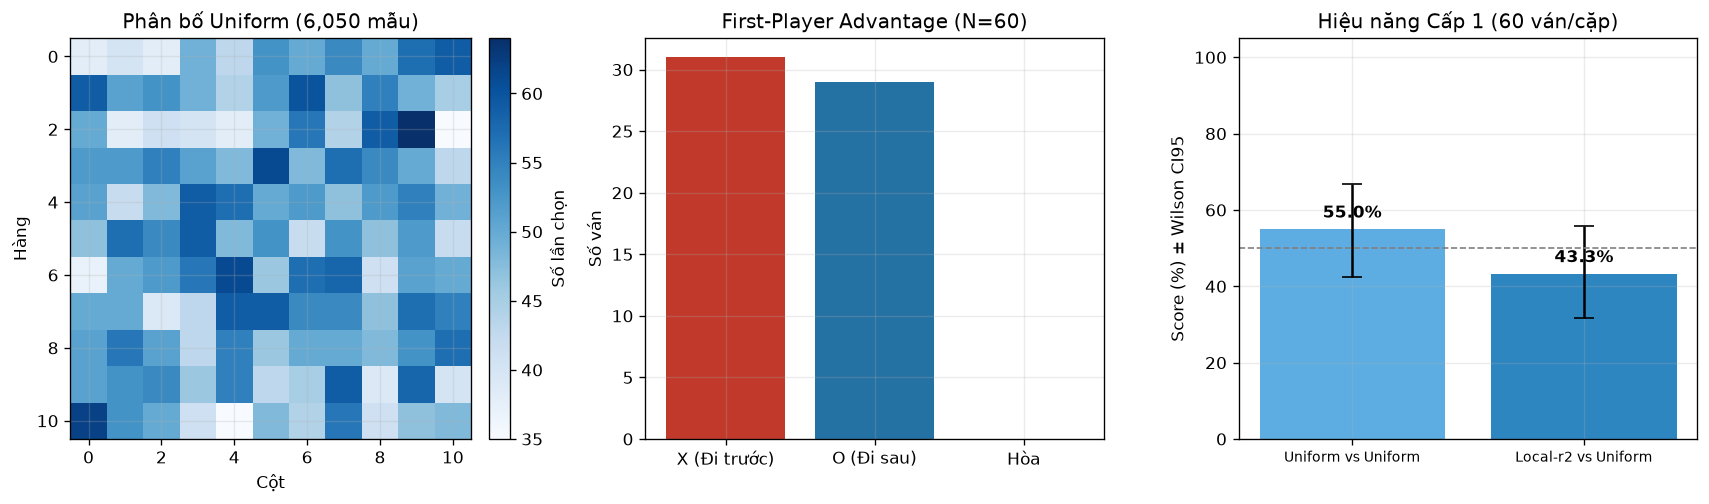

In [5]:
rng_agent = RandomAgent(seed=BASE_SEED)
empty_env = CaroEnv()
counts = np.zeros(121, dtype=np.int64)
n_samples = 6050 if RUN_MODE == "quick" else 24200
for _ in range(n_samples):
    counts[rng_agent.select_action(empty_env)] += 1

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

im = axes[0].imshow(counts.reshape(11, 11), cmap="Blues")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="Số lần chọn")
axes[0].set_title(f"Phân bố Uniform ({n_samples:,} mẫu)")
axes[0].set_xlabel("Cột")
axes[0].set_ylabel("Hàng")

# First-player advantage bar
axes[1].bar(["X (Đi trước)", "O (Đi sau)", "Hòa"], [x_w, o_w, d_w], color=["#c0392b", "#2471a3", "#7f8c8d"])
axes[1].set_ylabel("Số ván")
axes[1].set_title(f"First-Player Advantage (N={len(u_logs)})")

# Score comparison
scores = df_lv1["score_pct"].tolist()
yerr_lo = [s - lo for s, lo in zip(scores, df_lv1["ci95_low"])]
yerr_hi = [hi - s for s, hi in zip(scores, df_lv1["ci95_high"])]
bars = axes[2].bar([0, 1], scores, yerr=[yerr_lo, yerr_hi], capsize=6, color=["#5dade2", "#2e86c1"])
axes[2].axhline(50.0, color="gray", linestyle="--", linewidth=1)
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Uniform vs Uniform", "Local-r2 vs Uniform"], fontsize=8.5)
axes[2].set_ylim(0, 105)
axes[2].set_ylabel("Score (%) ± Wilson CI95")
axes[2].set_title(f"Hiệu năng Cấp 1 ({N_GAMES} ván/cặp)")
for b, s in zip(bars, scores):
    axes[2].text(b.get_x() + b.get_width() / 2, s + 3, f"{s:.1f}%", ha="center", fontweight="bold")

fig_path = FIGURES_DIR / "01_level1_random_analysis.png"
plt.tight_layout()
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()


## 5. Tóm tắt Kết luận & Hạn chế 

- **Kết luận thực nghiệm:** `RandomAgent` chọn đồng đều trên toàn bộ 121 ô (độ trễ `< 0.01 ms/nước`), tái lập tuyệt đối theo `seed`. Kết quả `Random vs Random` cho thấy người đi trước `X` có lợi thế tự nhiên nhẹ do luôn đi hơn `O` một nước khi tạo chuỗi 5 quân.
- **Nhận xét về `local_random_r2`:** chỉ tập trung ngẫu nhiên gần quân cũ nhưng không đánh giá hướng thắng/chặn nên dễ giúp đối thủ ghép chuỗi 5 ở vùng trung tâm nếu không có luật chặn.
- **Hạn chế & Vai trò:** Cấp 1 hoàn toàn không có chiến thuật; vai trò chính là **mốc chuẩn tối thiểu (sanity baseline)** để kiểm chứng các Cấp 2–7 phải đạt xấp xỉ **100%** khi đối đầu.
